# Porównanie bibliotek Pose Estimation na nagraniach wybranych ćwiczeń

**Issue #4:** *Compare libraries proposed in python cv libraries ADR based on recordings provided*

Poprzedni benchmark ([`benchmark_results.md`](../../docs/adr/001-python-cv-libraries-analysis/benchmark_results.md)) mierzył 4 biblioteki na nagraniach **wyciskania leżąc**, którego nie ma wśród wybranych ćwiczeń. Ten notebook powtarza porównanie na **nagraniach wzorcowych z [`docs/exercises/`](../../docs/exercises/)** (pompki, podciąganie, OHP), w ujęciach kamery opisanych dla każdego ćwiczenia.

Oprócz szybkości i odsetka wykrytych klatek sprawdzamy to, co jest potrzebne do zliczania powtórzeń:

| Pytanie | Metryka |
| :--- | :--- |
| Czy model widzi stawy potrzebne do kąta łokcia? | % klatek z kompletem punktów (bark, łokieć, nadgarstek) o pewności ≥ 0,3 |
| Czy zmieści się w czasie rzeczywistym? | mediana i 95. percentyl czasu inferencji na CPU |
| Czy sygnał kąta jest stabilny? | szum: mediana \|θ[t+1] − 2θ[t] + θ[t−1]\| (°) |
| Czy kąt zgadza się z innymi modelami? | mediana \|θ − mediana kątów pozostałych bibliotek\| (°) |
| Czy progi z `docs/exercises` działają na tym sygnale? | liczba powtórzeń vs. policzona ręcznie |

**Uruchomienie od zera:** `pip install -r requirements.txt`, potem `python pose_compare.py --download` (filmy do `data/`) i `python pose_compare.py` (ekstrakcja do `results/exercise_benchmark/`, ok. 20 min na CPU). Notebook wczytuje wyniki z cache.

In [1]:
import logging
import platform
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import cv2
import io
from IPython.display import Image, display

import pose_compare as pc

pd.set_option("display.precision", 1)
pd.set_option("display.max_colwidth", 80)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # no Segoe UI (Linux/Mac) -> silent fallback

RELAX = 15  # sensitivity analysis: by how many degrees to lower the elbow extension thresholds from docs/exercises

# Fixed colour per library on all charts (reference palette, slots 1–4)
LIB_COLORS = {"MediaPipe": "#257de0", "YOLO-Pose": "#f47230", "MoveNet": "#00b894", "RTMPose": "#f2a600"}
INK, INK_2, GRID, AXIS = "#191919", "#666666", "#e7e7e7", "#c2c2c2"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cce3fd", "#9dc8f7", "#6aabf1", "#338ced", "#2370cd", "#1757ac", "#0e3d7e"]
)

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 9.5,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 1.6, "figure.dpi": 110,
})

# One variant per library for the angle-over-time charts (the more accurate variant of each family)
REPRESENTATIVE = {"MediaPipe": "mediapipe_full", "YOLO-Pose": "yolo11n", "MoveNet": "movenet_thunder", "RTMPose": "rtmpose_balanced"}
MODEL_KEYS = [m.key for m in pc.MODELS]
VIDEO_KEYS = [v.key for v in pc.VIDEOS]

## 1. Sprzęt i wersje

Wszystkie modele działają **na CPU** (docelowo telefon, bez GPU), z tymi samymi progami co skrypty `test_*.py`. Komputer jest inny niż w poprzednim benchmarku, więc **czasy bezwzględne nie są porównywalne** z `benchmark_results.md`, porównywalna jest kolejność modeli.

In [2]:
def cpu_name() -> str:
    try:
        import winreg
        key = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
        return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    except Exception:
        return platform.processor() or "nieznany"

from importlib.metadata import version
libs = ["mediapipe", "ultralytics", "torch", "ai-edge-litert", "rtmlib", "onnxruntime", "opencv-python"]
print(f"CPU     : {cpu_name()}")
print(f"Python  : {platform.python_version()} ({platform.system()} {platform.release()})")
for name in libs:
    print(f"{name:14s}: {version(name)}")

CPU     : AMD Ryzen 5 7600X 6-Core Processor
Python  : 3.13.5 (Windows 11)
mediapipe     : 1.2.3
ultralytics   : 8.4.218
torch         : 2.15.0
ai-edge-litert: 2.4.0
rtmlib        : 0.0.16
onnxruntime   : 1.32.0
opencv-python : 5.1.0.95


## 2. Nagrania wzorcowe

Linki pochodzą z sekcji *Reference Videos* w `docs/exercises/*.md`. Z każdego filmu wybrany jest fragment, na którym widać ćwiczenie w docelowym ujęciu (bez plansz, gadania do kamery i zbliżeń). **Liczba powtórzeń została policzona ręcznie** klatka po klatce (co 0,25 s). Powtórzenie to pełny cykl z dokumentacji: pozycja startowa → pełny zakres → powrót.

Nagrania z YouTube odbiegają od zaleceń z `docs/exercises` (np. podciąganie jest nagrane prawie od tyłu, a nie pod kątem 25–30°, a w filmie Scotta Hermana nie widać nóg). Dlatego dobrze sprawdzają odporność modeli na warunki, jakie zdarzą się u użytkowników.

In [3]:
def fmt_ts(s: float) -> str:
    return f"{int(s // 60)}:{s % 60:04.1f}"

missing = [v.key for v in pc.VIDEOS if not v.path.exists()]
assert not missing, f"Brak nagrań {missing} - uruchom: python pose_compare.py --download"

rows = []
for v in pc.VIDEOS:
    cap = cv2.VideoCapture(str(v.path))
    fps, w, h = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    rows.append({
        "nagranie": v.key,
        "ćwiczenie": pc.EXERCISE_LABELS[v.exercise],
        "ujęcie": v.view,
        "fragment": ", ".join(f"{fmt_ts(s)}–{fmt_ts(e)}" for s, e in v.segments),
        "długość [s]": sum(e - s for s, e in v.segments),
        "FPS": round(fps, 2),
        "rozdzielczość": f"{w}×{h}",
        "powtórzenia (ręcznie)": v.true_reps,
        "uwagi": v.note,
    })
display(pd.DataFrame(rows).set_index("nagranie"))

,ćwiczenie,ujęcie,fragment,długość [s],FPS,rozdzielczość,powtórzenia (ręcznie),uwagi
nagranie,,,,,,,,
push_up_side,Pompki,bok 90°,2:06.4–2:15.7,9.3,24.0,1280×720,2,"Video 2 z push_up.md (2:06–2:16, wolne powtórzenia, idealny profil)"
push_up_angles,Pompki,ukos ~45°,3:05.5–3:24.3,18.8,24.0,1280×720,8,"Video 1 z push_up.md (3:05–3:24, ujęcie skośne bok/przód)"
pull_up_rear_diagonal,Podciąganie,tył / lekki ukos,0:05.2–0:21.5,16.2,30.0,1280×720,6,"Video 1 z pull_up.md (0:05–0:21, kamera blisko, nogi częściowo poza kadrem)"
pull_up_front,Podciąganie,"przód, z daleka",0:01.0–0:15.6,14.6,30.0,1280×720,11,"Video 2 z pull_up.md (0:01–0:15, szybkie powtórzenia, osoba ~40% wysokości k..."
ohp_thrall,OHP,ukos od przodu ~30°,"2:00.2–2:05.6, 2:09.8–2:14.7",10.3,60.0,1280×720,1,"Video 1 z over_head_press.md (2:00–2:05 i 2:10–2:15, dwa ujęcia przedzielone..."
ohp_nasm,OHP,ukos od przodu 45°,0:00.0–0:11.4,11.4,30.0,1280×720,3,"Video 2 z over_head_press.md (cały film, studyjne nagranie na sztucznym tle)"
ohp_scott_herman,OHP,"przód, bez nóg",1:57.0–2:23.9,26.9,24.0,1280×720,4,"Video 3 z over_head_press.md (1:57–2:24, nogi poza kadrem, kamera lekko się ..."


## 3. Modele i ekstrakcja punktów

Te same 8 wariantów co w poprzednim benchmarku. Każdy model zwraca 17 punktów w formacie COCO (MediaPipe zwraca 33, z których bierzemy odpowiadające 17), więc kąty liczymy tym samym kodem. Nagrania 60 FPS są próbkowane co 2. klatkę, żeby wszystkie miały ~24–30 FPS. Przy kilku osobach w kadrze bierzemy największą.

**MoveNet Thunder** w poprzednim benchmarku miał `ERROR`, bo nie udawało się pobrać modelu. Stare linki API Kaggle w `test_movenet.py` zwracają 404, a nagłówek `User-Agent: Mozilla/5.0` blokuje też oficjalne przekierowanie z TF Hub. `pose_compare.py` pobiera model z TF Hub z domyślnym nagłówkiem i Thunder działa.

In [4]:
RUN_MISSING = True   # True = compute missing (recording, model) pairs; full extraction takes ~20 min on CPU

results = {}
for v in pc.VIDEOS:
    for m in pc.MODELS:
        if RUN_MISSING or pc.result_path(v.key, m.key).exists():
            results[(v.key, m.key)] = pc.extract(v, m.key)

n_frames = {v.key: len(results[(v.key, MODEL_KEYS[0])]) for v in pc.VIDEOS}
assert all(len(results[(v.key, m.key)]) == n_frames[v.key] for v in pc.VIDEOS for m in pc.MODELS), "różna liczba klatek"
print(f"Wczytano {len(results)} par (nagranie, model), {sum(n_frames.values())} klatek na model")

Wczytano 56 par (nagranie, model), 2895 klatek na model


In [5]:
# Elbow angle for every frame: side view - the side closer to the camera, other views - mean of both arms
SIDES = {}
for v in pc.VIDEOS:
    SIDES[v.key] = pc.pick_side([results[(v.key, m.key)] for m in pc.MODELS]) if v.side == "auto" else "both"
ELBOW = {(vk, mk): pc.exercise_angle(df, pc.VIDEOS_BY_KEY[vk], SIDES[vk]) for (vk, mk), df in results.items()}


def others_median(vk: str, library: str) -> pd.Series:
    # Median angle of the representatives of the OTHER libraries (excluding the model's own family)
    series = [ELBOW[(vk, mk)] for lib, mk in REPRESENTATIVE.items() if lib != library]
    return pd.concat(series, axis=1).median(axis=1, skipna=True)


records = []
for (vk, mk), df in results.items():
    v, m = pc.VIDEOS_BY_KEY[vk], pc.MODELS_BY_KEY[mk]
    angle = ELBOW[(vk, mk)]
    reps, _ = pc.count_reps_for(df, v, angle)
    reps_relaxed, _ = pc.count_reps_for(df, v, angle, extension_offset=RELAX)
    records.append({
        "video": vk, "model": mk, "library": m.library,
        "detected_pct": 100 * df["detected"].mean(),
        "usable_pct": 100 * angle.notna().mean(),
        "jitter_deg": pc.jitter(angle),
        "dev_others_deg": float((angle - others_median(vk, m.library)).abs().median()),
        "reps": reps, "reps_relaxed": reps_relaxed, "true_reps": v.true_reps,
        **pc.latency_stats(df),
    })
metrics = pd.DataFrame(records)

# Inference time: all frames from all recordings (excluding model warm-up at the start of each recording)
latency = {
    mk: pd.concat([results[(vk, mk)]["latency_ms"].iloc[pc.WARMUP_FRAMES:] for vk in VIDEO_KEYS])
    for mk in MODEL_KEYS
}
print("Strona ciała użyta do kąta łokcia:", SIDES)

Strona ciała użyta do kąta łokcia: {'push_up_side': 'right', 'push_up_angles': 'left', 'pull_up_rear_diagonal': 'both', 'pull_up_front': 'both', 'ohp_thrall': 'both', 'ohp_nasm': 'both', 'ohp_scott_herman': 'both'}


### Podgląd: ten sam moment, 4 biblioteki

Dla każdego nagrania pokazujemy klatkę z najtrudniejszej fazy ruchu: dół pompki, górę podciągnięcia i wyprost OHP. Punkty o pewności < 0,3 nie są rysowane.

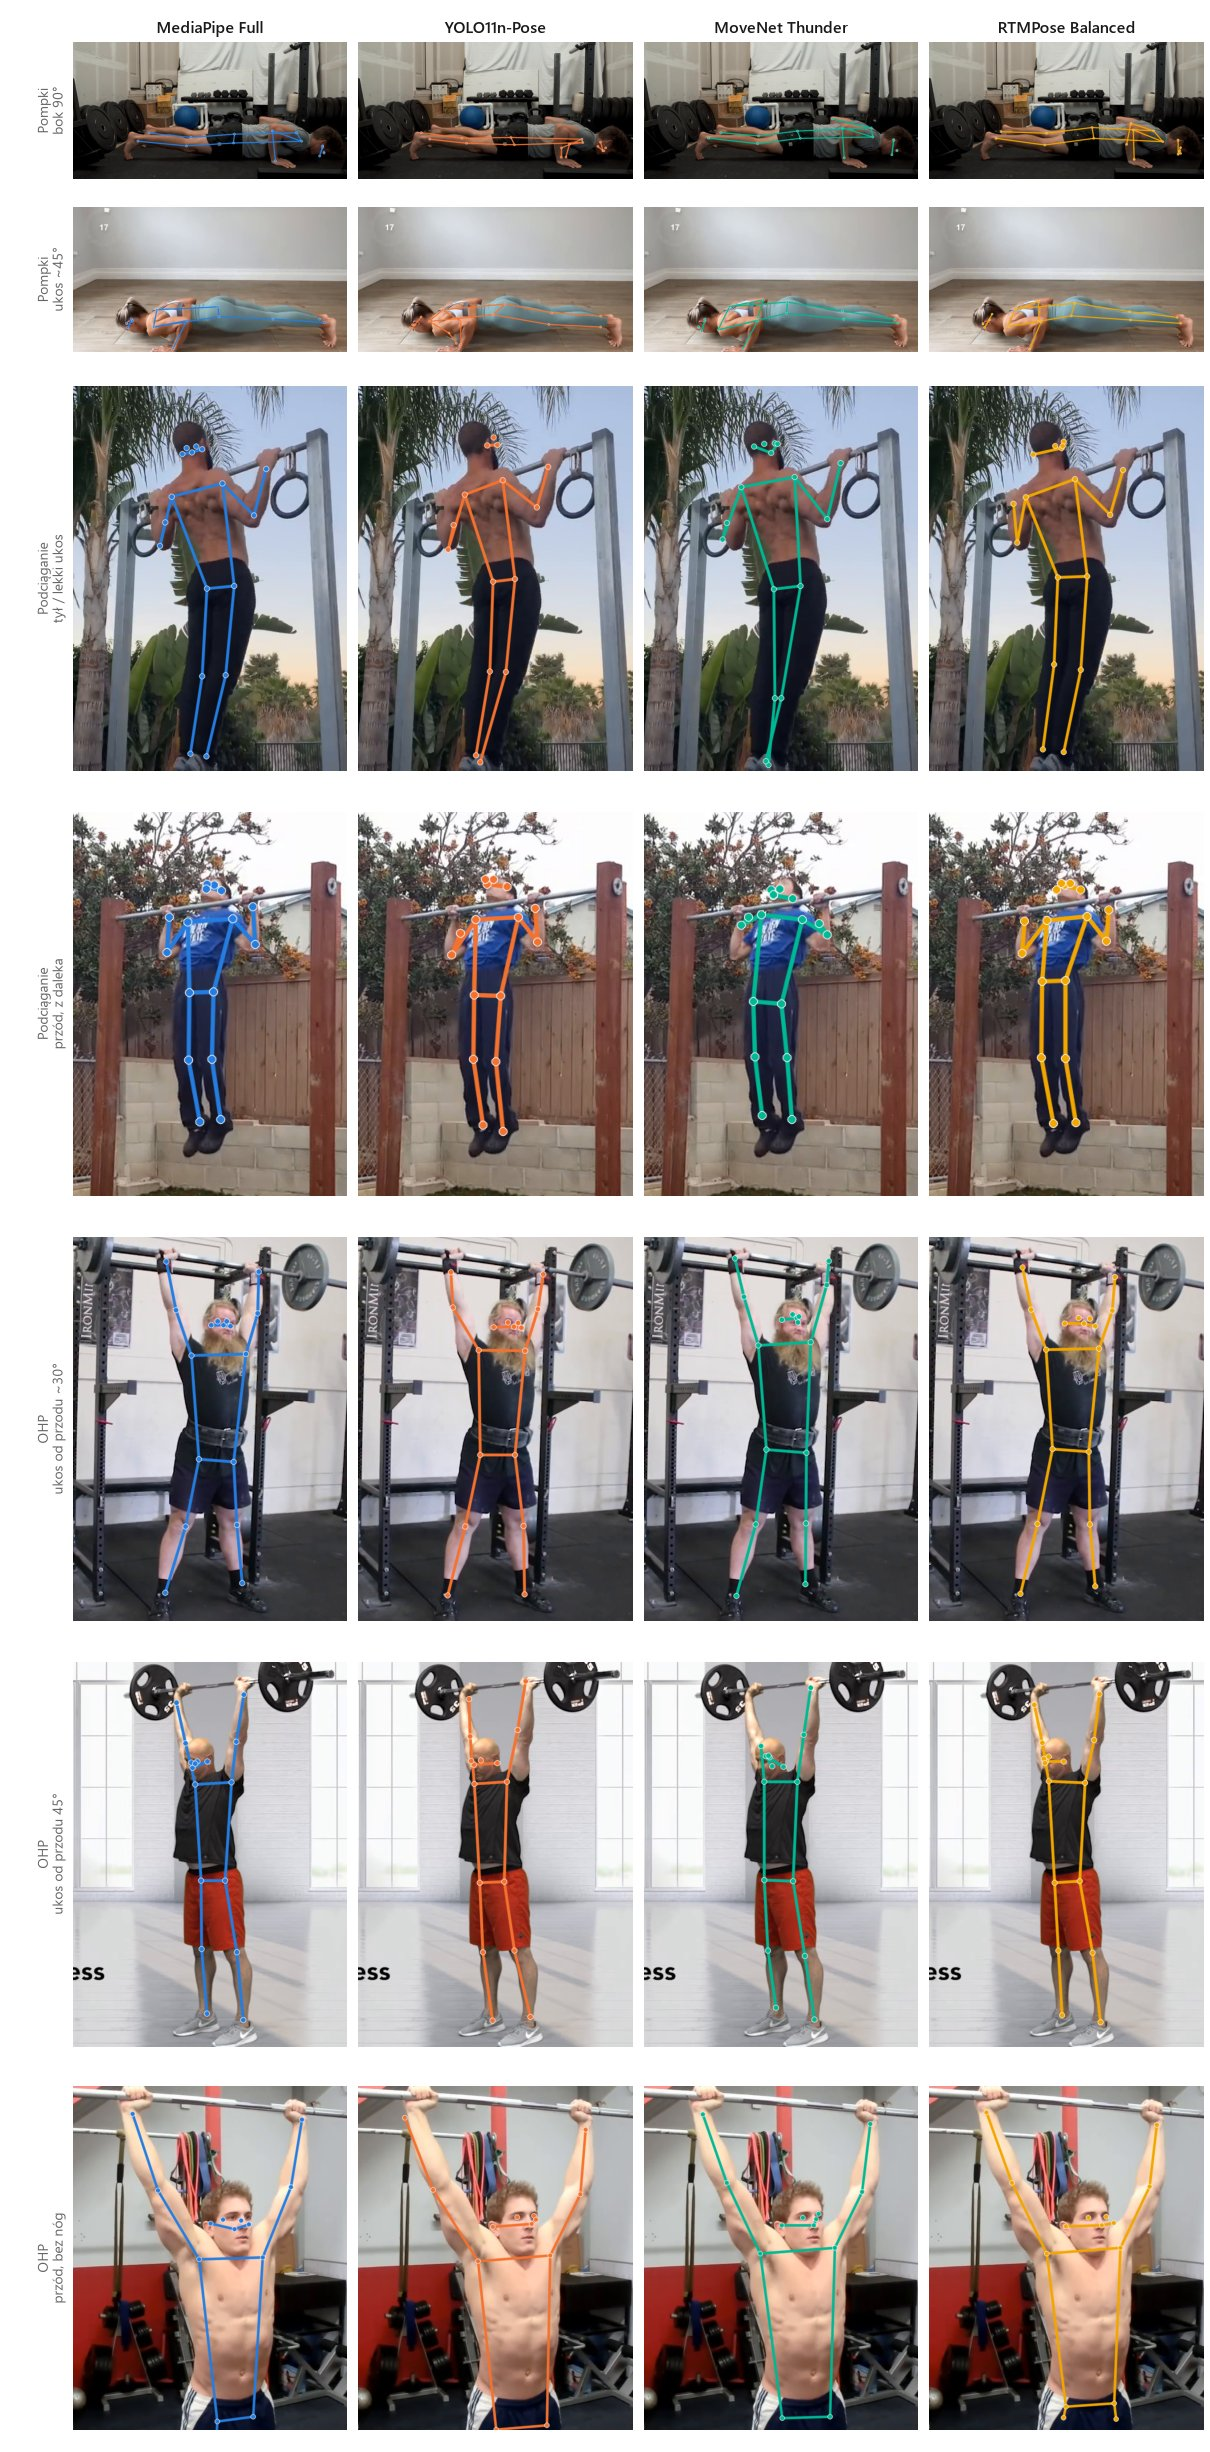

In [6]:
def hex_to_bgr(h: str) -> tuple[int, int, int]:
    h = h.lstrip("#")
    return int(h[4:6], 16), int(h[2:4], 16), int(h[0:2], 16)


def key_frame_row(vk: str) -> int:
    # Row where the median angle of the 4 libraries is most extreme for the phase (all 4 detected the person)
    v = pc.VIDEOS_BY_KEY[vk]
    angles = pd.concat([ELBOW[(vk, mk)] for mk in REPRESENTATIVE.values()], axis=1)
    consensus = angles.median(axis=1).where(angles.notna().all(axis=1))
    return int(consensus.idxmax() if v.exercise == "ohp" else consensus.idxmin())


def crop_box(vk: str, row: int, shape, margin: float = 0.2, aspect=(0.5, 1.4)):
    # Box around the keypoints of the 4 models + margin, expanded to a height/width ratio within `aspect`
    pts = []
    for mk in REPRESENTATIVE.values():
        r = results[(vk, mk)].iloc[row]
        for name in pc.COCO_KEYPOINTS:
            if r.get(f"{name}_c", 0) >= pc.MIN_KP_CONF:
                pts.append((r[f"{name}_x"], r[f"{name}_y"]))
    pts = np.array(pts)
    (x0, y0), (x1, y1) = pts.min(axis=0), pts.max(axis=0)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    bw, bh = (x1 - x0) * (1 + 2 * margin) + 40, (y1 - y0) * (1 + 2 * margin) + 40
    bh = min(max(bh, bw * aspect[0]), shape[0])
    bw = min(max(bw, bh / aspect[1]), shape[1])
    x0 = int(np.clip(cx - bw / 2, 0, shape[1] - bw)); y0 = int(np.clip(cy - bh / 2, 0, shape[0] - bh))
    return x0, y0, int(x0 + bw), int(y0 + bh)


libs = list(REPRESENTATIVE)
key_rows = {v.key: key_frame_row(v.key) for v in pc.VIDEOS}
crops, frames = {}, {}
for v in pc.VIDEOS:
    frames[v.key] = pc.read_frame(v, int(results[(v.key, MODEL_KEYS[0])].iloc[key_rows[v.key]]["frame"]))
    crops[v.key] = crop_box(v.key, key_rows[v.key], frames[v.key].shape)
ratios = [(c[3] - c[1]) / (c[2] - c[0]) for c in crops.values()]
col_w = 11 / len(libs)
fig, axes = plt.subplots(
    len(pc.VIDEOS), len(libs), figsize=(11, col_w * sum(ratios) + 0.6),
    gridspec_kw={"height_ratios": ratios, "hspace": 0.06, "wspace": 0.04},
)
for i, v in enumerate(pc.VIDEOS):
    row, frame = key_rows[v.key], frames[v.key]
    x0, y0, x1, y1 = crops[v.key]
    for j, lib in enumerate(libs):
        mk = REPRESENTATIVE[lib]
        drawn = pc.draw_skeleton(frame, results[(v.key, mk)].iloc[row], hex_to_bgr(LIB_COLORS[lib]))
        ax = axes[i, j]
        ax.imshow(cv2.cvtColor(drawn[y0:y1, x0:x1], cv2.COLOR_BGR2RGB))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        if i == 0:
            ax.set_title(pc.MODELS_BY_KEY[mk].label, loc="center", color=INK)
        if j == 0:
            ax.set_ylabel(f"{pc.EXERCISE_LABELS[v.exercise]}\n{v.view}", fontsize=9, color=INK_2)
fig.subplots_adjust(left=0.06, right=0.995, top=1 - 0.35 / fig.get_figheight(), bottom=0.005)
buf = io.BytesIO()
fig.savefig(buf, format="jpg", dpi=110, pil_kwargs={"quality": 85})  # JPEG: these photos would weigh several MB as PNG
plt.close(fig)
display(Image(buf.getvalue()))

## 4. Wyniki

### 4.1 Czy model widzi potrzebne stawy?

Do liczenia powtórzeń wystarczą bark, łokieć i nadgarstek. Kąt da się policzyć tylko wtedy, gdy wszystkie trzy mają pewność ≥ 0,3. Przy ujęciu z przodu lub tyłu wystarczy jedna ręka.

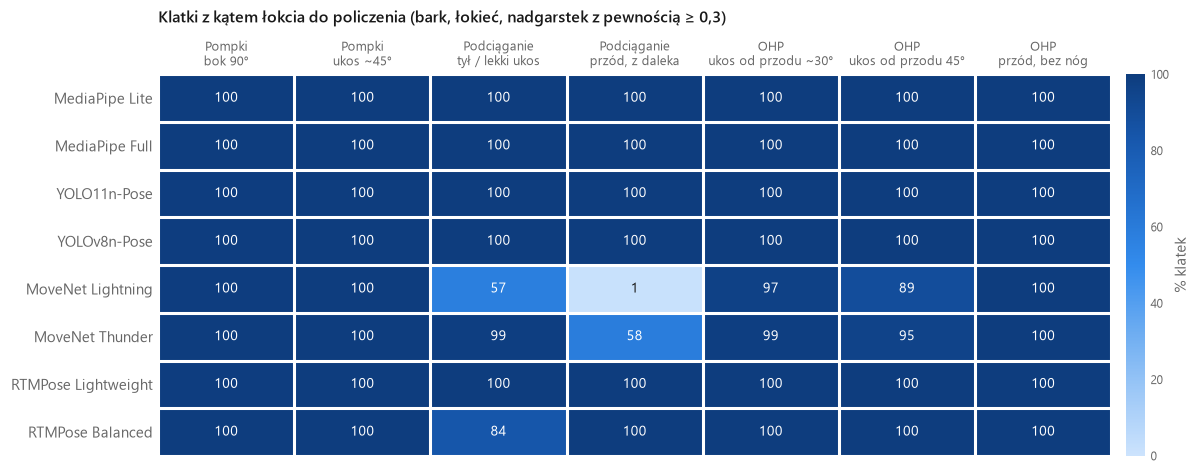

wykryta osoba [%]                              \
                             ohp_nasm ohp_scott_herman ohp_thrall   
MediaPipe Lite                    100              100        100   
MediaPipe Full                    100              100        100   
YOLO11n-Pose                      100              100        100   
YOLOv8n-Pose                      100              100        100   
MoveNet Lightning                 100              100        100   
MoveNet Thunder                   100              100        100   
RTMPose Lightweight               100              100        100   
RTMPose Balanced                  100              100        100   

                                                                        \
                    pull_up_front pull_up_rear_diagonal push_up_angles   
MediaPipe Lite                100                   100            100   
MediaPipe Full                100                   100            100   
YOLO11n-Pose                  100                   100            100   
YOLOv8n-Pose                  100                   100            100   
MoveNet Lightning             100                   100            100   
MoveNet Thunder               100                   100            100   
RTMPose Lightweight           100                   100            100   
RTMPose Balanced              100                   100            100   

                                 kąt łokcia [%]                              \
                    push_up_side       ohp_nasm ohp_scott_herman ohp_thrall   
MediaPipe Lite               100            100              100        100   
MediaPipe Full               100            100              100        100   
YOLO11n-Pose                 100            100              100        100   
YOLOv8n-Pose                 100            100              100        100   
MoveNet Lightning            100             89              100         97   
MoveNet Thunder              100             95              100         99   
RTMPose Lightweight          100            100              100        100   
RTMPose Balanced             100            100              100        100   

                                                                        \
                    pull_up_front pull_up_rear_diagonal push_up_angles   
MediaPipe Lite                100                   100            100   
MediaPipe Full                100                   100            100   
YOLO11n-Pose                  100                   100            100   
YOLOv8n-Pose                  100                   100            100   
MoveNet Lightning               1                    57            100   
MoveNet Thunder                58                    99            100   
RTMPose Lightweight           100                   100            100   
RTMPose Balanced              100                    84            100   

                                  
                    push_up_side  
MediaPipe Lite               100  
MediaPipe Full               100  
YOLO11n-Pose                 100  
YOLOv8n-Pose                 100  
MoveNet Lightning            100  
MoveNet Thunder              100  
RTMPose Lightweight          100  
RTMPose Balanced             100

In [7]:
def heatmap(ax, values: pd.DataFrame, fmt: str, vmin: float, vmax: float, cmap, label: str):
    im = ax.imshow(values.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    norm = (values.to_numpy(dtype=float) - vmin) / (vmax - vmin)
    for (i, j), val in np.ndenumerate(values.to_numpy(dtype=float)):
        if not np.isnan(val):
            ax.text(j, i, format(val, fmt), ha="center", va="center", fontsize=9,
                    color="white" if norm[i, j] > 0.55 else INK)
    ax.set_xticks(np.arange(-0.5, values.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, values.shape[0]), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)
    cbar = ax.figure.colorbar(im, ax=ax, fraction=0.025, pad=0.015)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0, labelsize=8)
    cbar.set_label(label, color=INK_2)
    return im


video_ticks = [f"{pc.EXERCISE_LABELS[v.exercise]}\n{v.view}" for v in pc.VIDEOS]
model_ticks = [pc.MODELS_BY_KEY[mk].label for mk in MODEL_KEYS]

usable = metrics.pivot(index="model", columns="video", values="usable_pct").loc[MODEL_KEYS, VIDEO_KEYS]
fig, ax = plt.subplots(figsize=(11, 4.4))
heatmap(ax, usable, ".0f", 0, 100, SEQ_BLUE, "% klatek")
ax.set_xticks(range(len(VIDEO_KEYS)), video_ticks, fontsize=8.5)
ax.set_yticks(range(len(MODEL_KEYS)), model_ticks)
ax.xaxis.tick_top()
ax.set_title("Klatki z kątem łokcia do policzenia (bark, łokieć, nadgarstek z pewnością ≥ 0,3)", pad=34)
fig.tight_layout()
plt.show()

table = metrics.pivot(index="model", columns="video", values=["detected_pct", "usable_pct"]).loc[MODEL_KEYS]
table.index = model_ticks
table.columns = pd.MultiIndex.from_tuples(
    [("wykryta osoba [%]" if a == "detected_pct" else "kąt łokcia [%]", b) for a, b in table.columns]
)
display(table.round(0).astype(int))

**Czy model wie, której ręki nie widzi?** W pompkach nagrywanych z boku dalsza ręka jest zasłonięta przez tułów. Jeśli model daje jej niską pewność, aplikacja może sama wybrać stronę bliżej kamery. Jeśli daje wysoką, to „zgaduje” zasłonięty łokieć z pełnym przekonaniem. Poniżej średnia pewność punktów bark–łokieć–nadgarstek dla obu stron.

In [8]:
side_conf = []
for v in pc.VIDEOS:
    if v.side != "auto":
        continue
    near = SIDES[v.key]
    far = "left" if near == "right" else "right"
    for mk in MODEL_KEYS:
        df = results[(v.key, mk)]
        mean_conf = lambda s: float(df[[f"{s}_{p}_c" for p in ("shoulder", "elbow", "wrist")]].mean().mean())
        side_conf.append({"model": pc.MODELS_BY_KEY[mk].label, "nagranie": v.key,
                          "strona bliżej kamery": mean_conf(near), "strona zasłonięta": mean_conf(far)})
side_conf = pd.DataFrame(side_conf).pivot(index="model", columns="nagranie").loc[model_ticks]
with pd.option_context("display.precision", 2):
    display(side_conf)

strona bliżej kamery              strona zasłonięta  \
nagranie                  push_up_angles push_up_side    push_up_angles   
model                                                                     
MediaPipe Lite                      0.99         0.99              0.46   
MediaPipe Full                      0.98         0.99              0.50   
YOLO11n-Pose                        0.95         0.94              0.89   
YOLOv8n-Pose                        0.95         0.96              0.73   
MoveNet Lightning                   0.73         0.66              0.50   
MoveNet Thunder                     0.75         0.77              0.57   
RTMPose Lightweight                 0.88         0.82              0.69   
RTMPose Balanced                    0.83         0.90              0.69   

                                  
nagranie            push_up_side  
model                             
MediaPipe Lite              0.52  
MediaPipe Full              0.47  
YOLO11n-Pose                0.86  
YOLOv8n-Pose                0.86  
MoveNet Lightning           0.53  
MoveNet Thunder             0.50  
RTMPose Lightweight         0.65  
RTMPose Balanced            0.72

### 4.2 Czy zmieści się w czasie rzeczywistym?

Mediana (kropka) i 95. percentyl (koniec kreski) czasu inferencji jednej klatki ze wszystkich nagrań. Oś jest logarytmiczna. Pionowa linia to 33 ms, czyli budżet na 30 FPS.

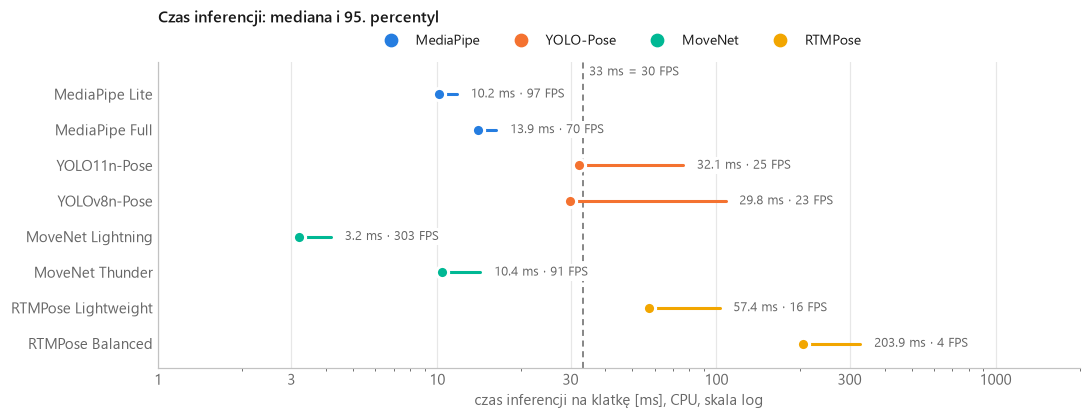

,mediana [ms],p95 [ms],średnie FPS
MediaPipe Lite,10.2,11.8,97.0
MediaPipe Full,13.9,16.3,69.9
YOLO11n-Pose,32.1,76.0,25.0
YOLOv8n-Pose,29.8,107.8,23.1
MoveNet Lightning,3.2,4.2,302.9
MoveNet Thunder,10.4,14.3,90.9
RTMPose Lightweight,57.4,102.6,16.2
RTMPose Balanced,203.9,328.0,4.5


In [9]:
fig, ax = plt.subplots(figsize=(10, 3.9))
ypos = np.arange(len(MODEL_KEYS))[::-1]
for y, mk in zip(ypos, MODEL_KEYS):
    m, lat = pc.MODELS_BY_KEY[mk], latency[mk]
    med, p95 = lat.median(), lat.quantile(0.95)
    color = LIB_COLORS[m.library]
    ax.plot([med, p95], [y, y], color=color, linewidth=2, solid_capstyle="round", zorder=2)
    ax.scatter([med], [y], s=64, color=color, edgecolor="white", linewidth=2, zorder=3)
    ax.text(p95 * 1.12, y, f"{med:.1f} ms · {1000 / lat.mean():.0f} FPS", va="center", fontsize=8.5, color=INK_2,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=4)
ax.axvline(1000 / 30, color=INK_2, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
ax.text(1000 / 30 * 1.05, ypos[0] + 0.45, "33 ms = 30 FPS", fontsize=8.5, color=INK_2, va="bottom",
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=4)
ax.set_xscale("log")
ax.set_xlim(1, 2000)
ax.set_ylim(-0.7, len(MODEL_KEYS) - 0.1)
ax.set_yticks(ypos, model_ticks)
ax.set_xticks([1, 3, 10, 30, 100, 300, 1000], ["1", "3", "10", "30", "100", "300", "1000"])
ax.set_xlabel("czas inferencji na klatkę [ms], CPU, skala log")
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[Line2D([], [], marker="o", linestyle="", markersize=8, color=c, label=lib) for lib, c in LIB_COLORS.items()],
    loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=4, fontsize=9,
)
ax.set_title("Czas inferencji: mediana i 95. percentyl", pad=26)
fig.tight_layout()
plt.show()

lat_table = pd.DataFrame({
    "mediana [ms]": {pc.MODELS_BY_KEY[k].label: v.median() for k, v in latency.items()},
    "p95 [ms]": {pc.MODELS_BY_KEY[k].label: v.quantile(0.95) for k, v in latency.items()},
    "średnie FPS": {pc.MODELS_BY_KEY[k].label: 1000 / v.mean() for k, v in latency.items()},
})
display(lat_table)

### 4.3 Przebieg kąta łokcia w czasie

Kąt łokcia z reprezentanta każdej biblioteki. Przerwy w linii oznaczają klatki, w których model nie widział stawów. Linie przerywane to progi z `docs/exercises/*.md`, których używa licznik powtórzeń. W OHP Thralla są dwa ujęcia przedzielone zbliżeniem.

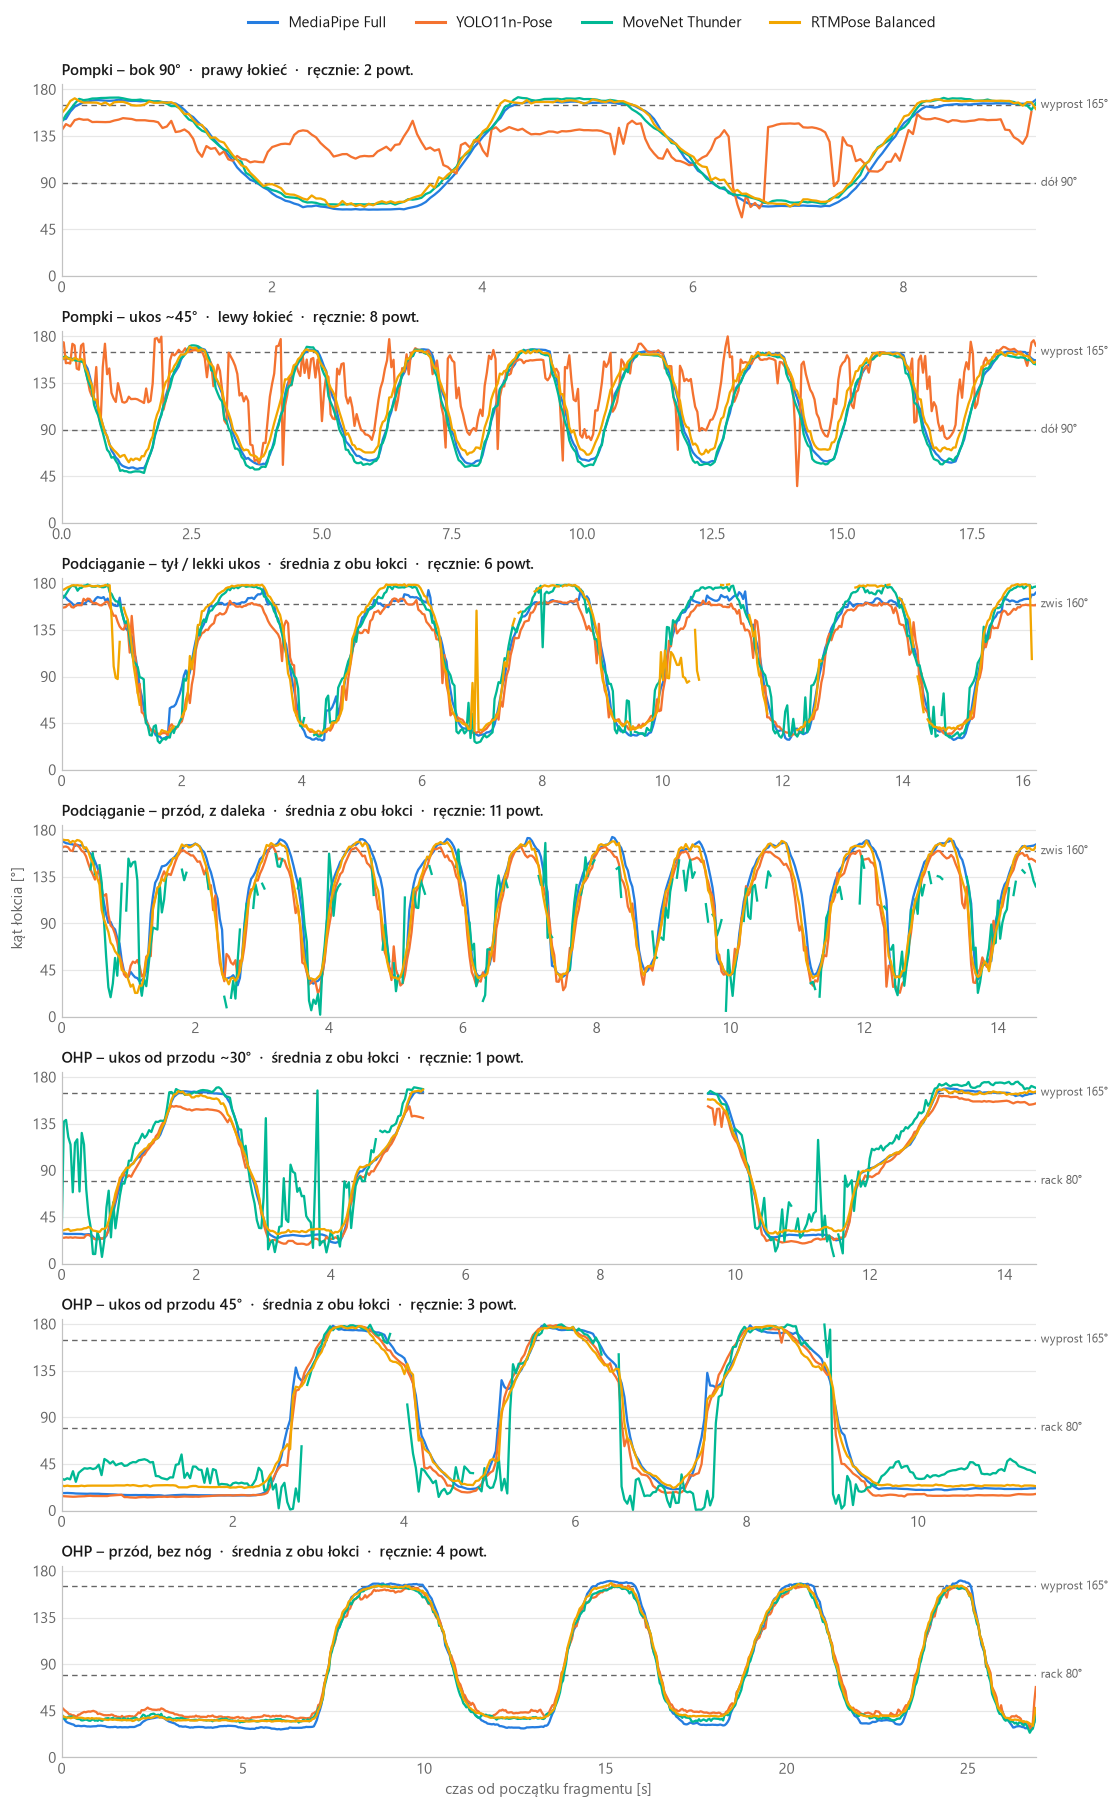

In [10]:
THRESHOLDS = {
    "push_up": [(165, "wyprost 165°"), (90, "dół 90°")],
    "pull_up": [(160, "zwis 160°")],
    "ohp": [(165, "wyprost 165°"), (80, "rack 80°")],
}

fig, axes = plt.subplots(len(pc.VIDEOS), 1, figsize=(11, 2.35 * len(pc.VIDEOS)), sharey=True)
for ax, v in zip(axes, pc.VIDEOS):
    for lib, mk in REPRESENTATIVE.items():
        df, angle = results[(v.key, mk)], ELBOW[(v.key, mk)]
        for _, idx in df.groupby("segment").groups.items():
            ax.plot(df.loc[idx, "t"], angle.loc[idx], color=LIB_COLORS[lib], linewidth=1.5)
    t_max = results[(v.key, MODEL_KEYS[0])]["t"].max()
    for value, label in THRESHOLDS[v.exercise]:
        ax.axhline(value, color=INK_2, linewidth=0.9, linestyle=(0, (4, 3)), zorder=1)
        ax.text(t_max * 1.005, value, label, fontsize=8, color=INK_2, va="center")
    side = {"left": "lewy łokieć", "right": "prawy łokieć", "both": "średnia z obu łokci"}[SIDES[v.key]]
    ax.set_title(f"{pc.EXERCISE_LABELS[v.exercise]} – {v.view}  ·  {side}  ·  ręcznie: {v.true_reps} powt.", fontsize=9.5)
    ax.set_ylim(0, 185)
    ax.set_yticks([0, 45, 90, 135, 180])
    ax.set_xlim(0, t_max)
    ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("czas od początku fragmentu [s]")
fig.supylabel("kąt łokcia [°]", color=INK_2, fontsize=9.5)
fig.legend(
    handles=[Line2D([], [], color=LIB_COLORS[lib], linewidth=2, label=pc.MODELS_BY_KEY[mk].label) for lib, mk in REPRESENTATIVE.items()],
    loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0), fontsize=9.5,
)
fig.tight_layout(rect=(0, 0, 0.94, 0.975))
plt.show()

### 4.4 Jakość sygnału kąta

* **Szum:** typowa zmiana prędkości kąta między kolejnymi klatkami. Prawdziwy ruch przy ~30 FPS jest gładki, więc wysoka wartość oznacza skaczące punkty.
* **Odchylenie od pozostałych bibliotek:** typowa różnica względem mediany kątów pozostałych trzech bibliotek. Nie mamy pomiaru referencyjnego (np. z czujników), więc to tylko wskaźnik zgodności, a nie dokładności.

Wartości to mediana z 7 nagrań. Im mniej, tym lepiej.

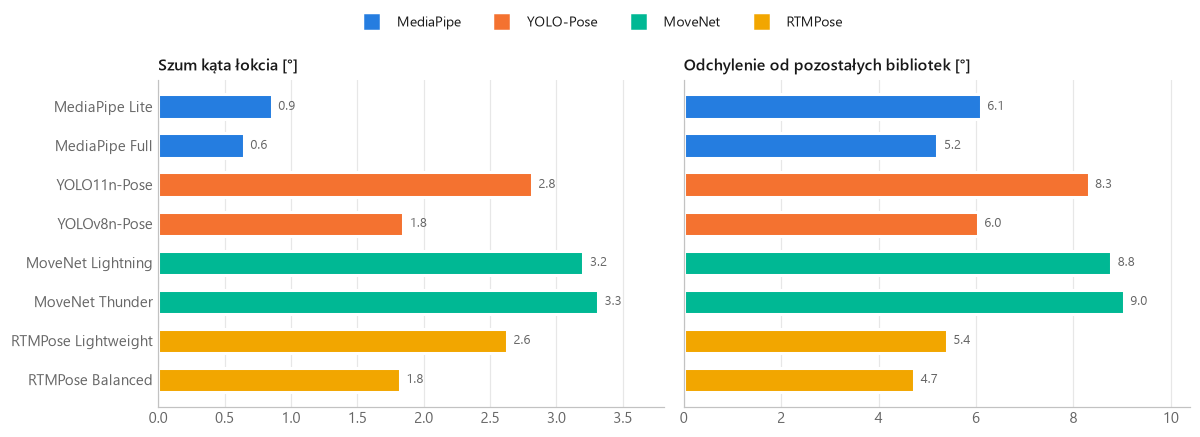

szum [°]                                            \
                    ohp_nasm ohp_scott_herman ohp_thrall pull_up_front   
MediaPipe Lite           0.7              0.6        0.9           2.7   
MediaPipe Full           0.4              0.5        0.6           2.1   
YOLO11n-Pose             0.6              1.0        1.1           4.9   
YOLOv8n-Pose             0.9              0.7        1.1           5.0   
MoveNet Lightning       23.0              1.9        9.4           NaN   
MoveNet Thunder          4.7              1.2        4.9          24.9   
RTMPose Lightweight      1.6              0.9        1.5           3.2   
RTMPose Balanced         1.1              0.7        1.4           3.4   

                                                                       \
                    pull_up_rear_diagonal push_up_angles push_up_side   
MediaPipe Lite                        2.1            1.2          0.7   
MediaPipe Full                        1.8            1.1          0.6   
YOLO11n-Pose                          2.8            8.5          3.1   
YOLOv8n-Pose                          1.8            4.3          2.1   
MoveNet Lightning                     3.9            2.5          1.8   
MoveNet Thunder                       3.3            2.1          1.1   
RTMPose Lightweight                   2.6            4.3          3.5   
RTMPose Balanced                      1.8            2.6          2.0   

                    odchylenie [°]                                            \
                          ohp_nasm ohp_scott_herman ohp_thrall pull_up_front   
MediaPipe Lite                 6.1              5.2        3.8           6.3   
MediaPipe Full                 5.4              5.1        2.8           8.7   
YOLO11n-Pose                   8.1              3.9        7.7           8.3   
YOLOv8n-Pose                   6.8              4.1        3.4           5.6   
MoveNet Lightning             42.3              5.2        8.8          18.8   
MoveNet Thunder               14.8              1.7       10.5          18.4   
RTMPose Lightweight            3.0              1.4        2.5           5.4   
RTMPose Balanced               6.4              1.4        3.3           4.7   

                                                                       
                    pull_up_rear_diagonal push_up_angles push_up_side  
MediaPipe Lite                        8.2            2.8          6.3  
MediaPipe Full                        6.9            5.2          4.2  
YOLO11n-Pose                         11.8           17.2         22.2  
YOLOv8n-Pose                          6.0           13.3         25.9  
MoveNet Lightning                    13.4            7.9          3.1  
MoveNet Thunder                       9.0            8.6          2.8  
RTMPose Lightweight                   9.9            9.0          8.6  
RTMPose Balanced                     10.2            6.2          2.7

In [11]:
summary_quality = metrics.groupby("model")[["jitter_deg", "dev_others_deg"]].median().loc[MODEL_KEYS]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
ypos = np.arange(len(MODEL_KEYS))[::-1]
colors = [LIB_COLORS[pc.MODELS_BY_KEY[mk].library] for mk in MODEL_KEYS]
for ax, col, title in [
    (axes[0], "jitter_deg", "Szum kąta łokcia [°]"),
    (axes[1], "dev_others_deg", "Odchylenie od pozostałych bibliotek [°]"),
]:
    vals = summary_quality[col].to_numpy()
    ax.barh(ypos, vals, height=0.62, color=colors, edgecolor="white", linewidth=2)
    for y, val in zip(ypos, vals):
        ax.text(val + vals.max() * 0.015, y, f"{val:.1f}", va="center", fontsize=8.5, color=INK_2)
    ax.set_title(title)
    ax.set_xlim(0, vals.max() * 1.15)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, model_ticks)
fig.legend(
    handles=[Line2D([], [], marker="s", linestyle="", markersize=9, color=c, label=lib) for lib, c in LIB_COLORS.items()],
    loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.02), fontsize=9,
)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

q_table = metrics.pivot(index="model", columns="video", values=["jitter_deg", "dev_others_deg"]).loc[MODEL_KEYS]
q_table.index = model_ticks
q_table.columns = pd.MultiIndex.from_tuples([("szum [°]" if a == "jitter_deg" else "odchylenie [°]", b) for a, b in q_table.columns])
display(q_table.round(1))

### 4.5 Zliczanie powtórzeń według progów z `docs/exercises`

Prosty licznik (maszyna stanów, bez wygładzania) z regułami z dokumentacji ćwiczeń:

| Ćwiczenie | Pozycja startowa / końcowa | Wyzwalacz (pełny zakres) |
| :--- | :--- | :--- |
| Pompki | łokieć ≥ 165° | łokieć ≤ 90° |
| Podciąganie | łokcie ≥ 160° | głowa (nos/uszy) nad linią nadgarstków |
| OHP | łokcie ≤ 80° (rack) | łokcie ≥ 165° i nadgarstki nad głową |

To nie jest docelowy algorytm zliczania (to punkt 5 w `Wymagania.md`). Test sprawdza, **czy sygnał z danego modelu osiąga progi zapisane w dokumentacji**. Druga tabela to analiza wrażliwości: progi **wyprostu** obniżone o 15° (pompki i OHP 150°, zwis 145°), pozostałe bez zmian. Pokazuje, ile błędów wynika z samego progu, a ile z modelu.

In [12]:
truth = pd.Series({v.key: v.true_reps for v in pc.VIDEOS})


def fmt_rep(count: int, true: int) -> str:
    return f"{count} ✓" if count == true else f"{count} ({count - true:+d})"


def rep_table(column: str) -> pd.DataFrame:
    counts = metrics.pivot(index="model", columns="video", values=column).loc[MODEL_KEYS, VIDEO_KEYS]
    table = pd.DataFrame(
        [[fmt_rep(int(counts.loc[mk, vk]), truth[vk]) for vk in VIDEO_KEYS] for mk in MODEL_KEYS],
        index=model_ticks, columns=VIDEO_KEYS,
    )
    table.loc["ręcznie (wzorzec)"] = truth.astype(str)
    table["trafione"] = [f"{int((counts.loc[mk] == truth).sum())}/{len(VIDEO_KEYS)}" for mk in MODEL_KEYS] + [""]
    table["suma |błędów|"] = [int((counts.loc[mk] - truth).abs().sum()) for mk in MODEL_KEYS] + [""]
    return table


reps = metrics.pivot(index="model", columns="video", values="reps").loc[MODEL_KEYS, VIDEO_KEYS]
reps_relaxed = metrics.pivot(index="model", columns="video", values="reps_relaxed").loc[MODEL_KEYS, VIDEO_KEYS]
print("Progi z docs/exercises (wyprost 165° / zwis 160°):")
display(rep_table("reps"))
print(f"Progi wyprostu obniżone o {RELAX}° (wyprost {165 - RELAX}° / zwis {160 - RELAX}°):")
display(rep_table("reps_relaxed"))

Progi z docs/exercises (wyprost 165° / zwis 160°):


,push_up_side,push_up_angles,pull_up_rear_diagonal,pull_up_front,ohp_thrall,ohp_nasm,ohp_scott_herman,trafione,suma |błędów|
MediaPipe Lite,0 (-2),2 (-6),6 ✓,11 ✓,0 (-1),3 ✓,4 ✓,4/7,9
MediaPipe Full,2 ✓,5 (-3),6 ✓,11 ✓,1 ✓,3 ✓,4 ✓,6/7,3
YOLO11n-Pose,0 (-2),6 (-2),5 (-1),8 (-3),0 (-1),3 ✓,2 (-2),1/7,11
YOLOv8n-Pose,0 (-2),0 (-8),6 ✓,10 (-1),0 (-1),3 ✓,3 (-1),2/7,13
MoveNet Lightning,2 ✓,0 (-8),6 ✓,0 (-11),1 ✓,3 ✓,2 (-2),4/7,21
MoveNet Thunder,2 ✓,3 (-5),6 ✓,1 (-10),1 ✓,3 ✓,3 (-1),4/7,16
RTMPose Lightweight,2 ✓,0 (-8),6 ✓,11 ✓,1 ✓,3 ✓,4 ✓,6/7,8
RTMPose Balanced,2 ✓,4 (-4),6 ✓,11 ✓,1 ✓,3 ✓,4 ✓,6/7,4
ręcznie (wzorzec),2,8,6,11,1,3,4,,


Progi wyprostu obniżone o 15° (wyprost 150° / zwis 145°):


,push_up_side,push_up_angles,pull_up_rear_diagonal,pull_up_front,ohp_thrall,ohp_nasm,ohp_scott_herman,trafione,suma |błędów|
MediaPipe Lite,2 ✓,8 ✓,6 ✓,11 ✓,1 ✓,3 ✓,4 ✓,7/7,0
MediaPipe Full,2 ✓,8 ✓,6 ✓,11 ✓,1 ✓,3 ✓,4 ✓,7/7,0
YOLO11n-Pose,1 (-1),13 (+5),6 ✓,11 ✓,1 ✓,3 ✓,4 ✓,5/7,6
YOLOv8n-Pose,2 ✓,4 (-4),6 ✓,11 ✓,1 ✓,3 ✓,4 ✓,6/7,4
MoveNet Lightning,2 ✓,8 ✓,6 ✓,0 (-11),1 ✓,4 (+1),4 ✓,5/7,12
MoveNet Thunder,2 ✓,8 ✓,6 ✓,13 (+2),1 ✓,3 ✓,4 ✓,6/7,2
RTMPose Lightweight,2 ✓,8 ✓,6 ✓,11 ✓,1 ✓,3 ✓,4 ✓,7/7,0
RTMPose Balanced,2 ✓,8 ✓,9 (+3),11 ✓,1 ✓,3 ✓,4 ✓,6/7,3
ręcznie (wzorzec),2,8,6,11,1,3,4,,


### 4.6 Ujęcia skośne: kąt 2D a kąt 3D z MediaPipe

Kąt liczony na obrazie 2D zależy od ustawienia kamery: przy ujęciu skośnym ręka wyprostowana w stronę kamery wygląda na zgiętą. MediaPipe jako jedyny zwraca też współrzędne 3D w metrach (`pose_world_landmarks`), więc z tego samego wyniku można policzyć kąt niezależny od ujęcia. Poniżej porównanie dla nagrań, w których kąt to średnia z obu rąk (podciąganie, OHP).

,kąt 2D: 5.–95. percentyl,kąt 3D: 5.–95. percentyl,powt. 2D (docs),powt. 3D (docs),powt. 2D (−15°),powt. 3D (−15°),ręcznie
nagranie,,,,,,,
pull_up_rear_diagonal,32–167°,77–160°,6,6,6,6,6
pull_up_front,38–169°,92–166°,11,11,11,11,11
ohp_thrall,25–166°,89–157°,1,0,1,0,1
ohp_nasm,15–174°,77–158°,3,0,3,3,3
ohp_scott_herman,29–168°,86–167°,4,0,4,0,4


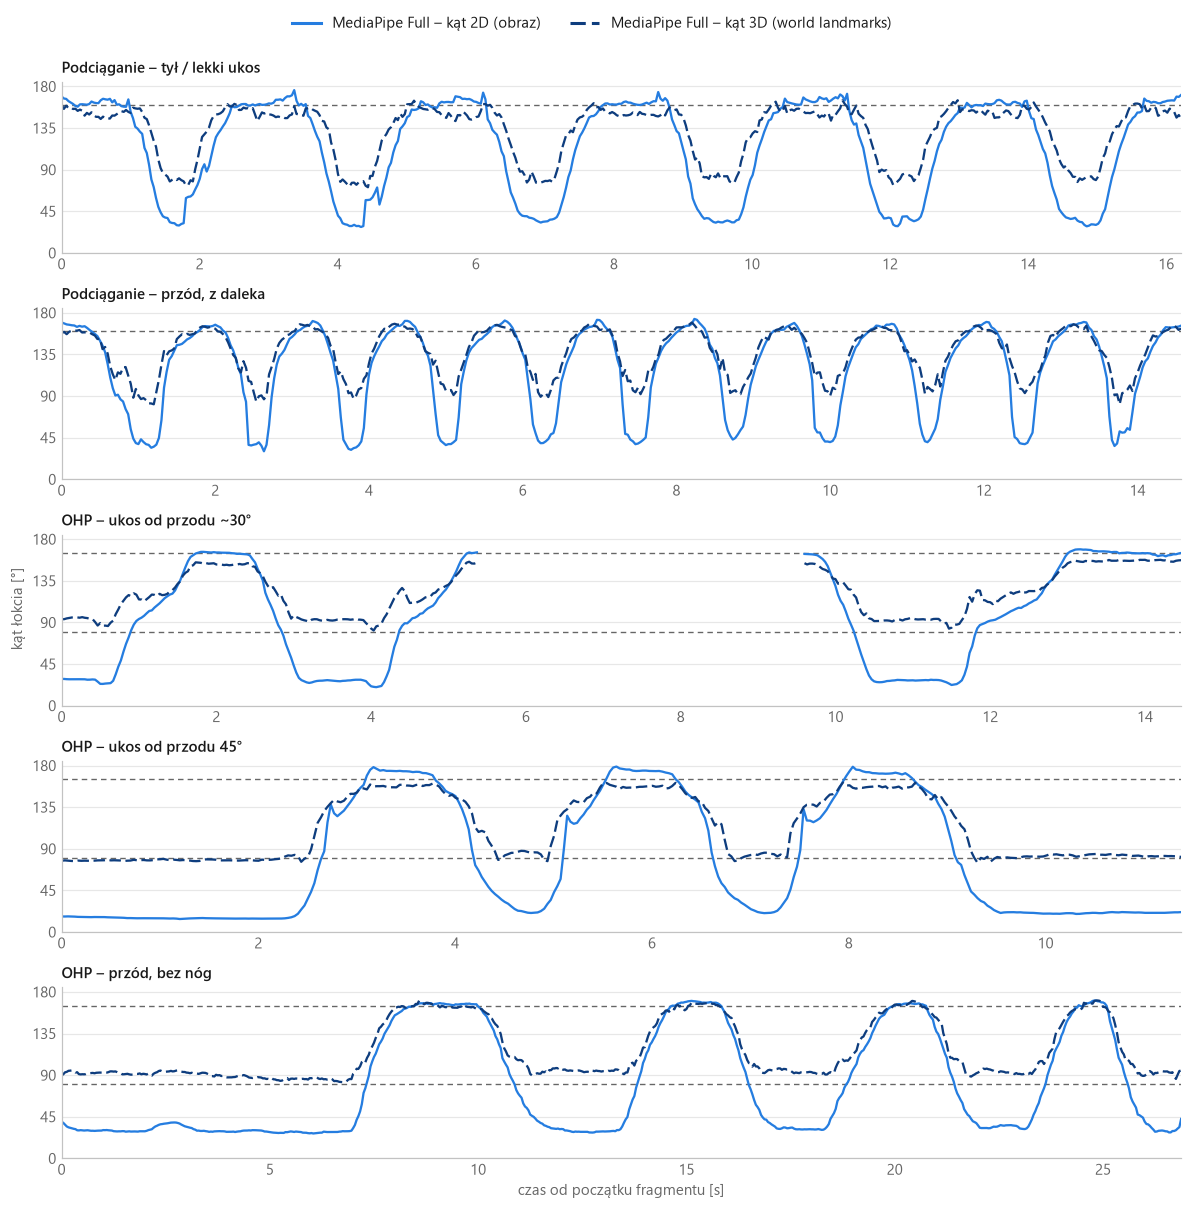

In [13]:
mp_key = "mediapipe_full"
rows_3d = []
for v in pc.VIDEOS:
    if SIDES[v.key] != "both":
        continue
    df = results[(v.key, mp_key)]
    a2, a3 = ELBOW[(v.key, mp_key)], pc.exercise_angle(df, v, "both", world=True)
    rows_3d.append({
        "nagranie": v.key,
        "kąt 2D: 5.–95. percentyl": f"{a2.quantile(0.05):.0f}–{a2.quantile(0.95):.0f}°",
        "kąt 3D: 5.–95. percentyl": f"{a3.quantile(0.05):.0f}–{a3.quantile(0.95):.0f}°",
        "powt. 2D (docs)": pc.count_reps_for(df, v, a2)[0],
        "powt. 3D (docs)": pc.count_reps_for(df, v, a3)[0],
        f"powt. 2D (−{RELAX}°)": pc.count_reps_for(df, v, a2, extension_offset=RELAX)[0],
        f"powt. 3D (−{RELAX}°)": pc.count_reps_for(df, v, a3, extension_offset=RELAX)[0],
        "ręcznie": v.true_reps,
    })
display(pd.DataFrame(rows_3d).set_index("nagranie"))

show = [v for v in pc.VIDEOS if SIDES[v.key] == "both"]
fig, axes = plt.subplots(len(show), 1, figsize=(11, 2.2 * len(show)), sharey=True)
for ax, v in zip(axes, show):
    df = results[(v.key, mp_key)]
    a2, a3 = ELBOW[(v.key, mp_key)], pc.exercise_angle(df, v, "both", world=True)
    for _, idx in df.groupby("segment").groups.items():
        ax.plot(df.loc[idx, "t"], a2.loc[idx], color=LIB_COLORS["MediaPipe"], linewidth=1.5)
        ax.plot(df.loc[idx, "t"], a3.loc[idx], color="#0e3d7e", linewidth=1.5, linestyle=(0, (5, 2)))
    for value, label in THRESHOLDS[v.exercise]:
        ax.axhline(value, color=INK_2, linewidth=0.9, linestyle=(0, (4, 3)), zorder=1)
    ax.set_title(f"{pc.EXERCISE_LABELS[v.exercise]} – {v.view}", fontsize=9.5)
    ax.set_ylim(0, 185)
    ax.set_yticks([0, 45, 90, 135, 180])
    ax.set_xlim(0, df["t"].max())
    ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("czas od początku fragmentu [s]")
fig.supylabel("kąt łokcia [°]", color=INK_2, fontsize=9.5)
fig.legend(
    handles=[
        Line2D([], [], color=LIB_COLORS["MediaPipe"], linewidth=2, label="MediaPipe Full – kąt 2D (obraz)"),
        Line2D([], [], color="#0e3d7e", linewidth=2, linestyle=(0, (5, 2)), label="MediaPipe Full – kąt 3D (world landmarks)"),
    ],
    loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0), fontsize=9.5,
)
fig.tight_layout(rect=(0, 0, 1, 0.965))
plt.show()

## 5. Podsumowanie

In [14]:
summary = pd.DataFrame({
    "biblioteka": [pc.MODELS_BY_KEY[mk].library for mk in MODEL_KEYS],
    "kąt łokcia, śr. % klatek": metrics.groupby("model")["usable_pct"].mean().loc[MODEL_KEYS].to_numpy(),
    "najgorsze nagranie [%]": metrics.groupby("model")["usable_pct"].min().loc[MODEL_KEYS].to_numpy(),
    "mediana czasu [ms]": [latency[mk].median() for mk in MODEL_KEYS],
    "szum [°]": summary_quality["jitter_deg"].to_numpy(),
    "odchylenie [°]": summary_quality["dev_others_deg"].to_numpy(),
    "powt. trafione (docs)": [int((reps.loc[mk] == truth).sum()) for mk in MODEL_KEYS],
    f"powt. trafione (−{RELAX}°)": [int((reps_relaxed.loc[mk] == truth).sum()) for mk in MODEL_KEYS],
    f"suma |błędów| (−{RELAX}°)": [int((reps_relaxed.loc[mk] - truth).abs().sum()) for mk in MODEL_KEYS],
}, index=model_ticks)
display(summary.round(1))

,biblioteka,"kąt łokcia, śr. % klatek",najgorsze nagranie [%],mediana czasu [ms],szum [°],odchylenie [°],powt. trafione (docs),powt. trafione (−15°),suma |błędów| (−15°)
MediaPipe Lite,MediaPipe,100.0,100.0,10.2,0.9,6.1,4,7,0
MediaPipe Full,MediaPipe,100.0,100.0,13.9,0.6,5.2,6,7,0
YOLO11n-Pose,YOLO-Pose,99.9,99.6,32.1,2.8,8.3,1,5,6
YOLOv8n-Pose,YOLO-Pose,99.9,99.6,29.8,1.8,6.0,2,6,4
MoveNet Lightning,MoveNet,77.8,1.4,3.2,3.2,8.8,4,5,12
MoveNet Thunder,MoveNet,93.0,58.4,10.4,3.3,9.0,4,6,2
RTMPose Lightweight,RTMPose,99.9,99.6,57.4,2.6,5.4,6,7,0
RTMPose Balanced,RTMPose,97.7,83.8,203.9,1.8,4.7,6,6,3


### Wnioski

**Decyzja z ADR 001 się potwierdza: MediaPipe Pose jest najlepszym wyborem także na nagraniach pompek, podciągania i OHP.**

1. **Wykrywanie osoby nie różnicuje już modeli.** Przy wyciskaniu leżąc MoveNet Lightning na jednym nagraniu wykrywał osobę tylko na 34% klatek. Tu wszystkie 8 wariantów wykrywa ją na 99,6–100% klatek. Różnice widać dopiero w jakości samych punktów.
2. **MediaPipe (Lite i Full)** ma komplet punktów do kąta łokcia na 100% klatek każdego nagrania. Ma też najmniejszy szum (0,6–0,9°) i zgodność z innymi bibliotekami na poziomie RTMPose (5,2–6,1°). Na CPU działa w 10–14 ms na klatkę (70–97 FPS), z małym rozrzutem (p95 12–16 ms). Ma też największą różnicę pewności między ręką widoczną a zasłoniętą (~0,99 wobec ~0,5), więc aplikacja może sama wybrać stronę bliżej kamery. Z progami wyprostu −15° oba warianty policzyły powtórzenia bezbłędnie na 7/7 nagrań.
3. **RTMPose** jest równie dokładny (odchylenie 4,7–5,4°, 7/7 dla Lightweight przy progach −15°), ale nie mieści się w budżecie 30 FPS na CPU: Lightweight 57 ms, Balanced 204 ms na klatkę. Wynik jest z desktopowego Ryzena 5 7600X, na telefonie będzie gorzej. Balanced na nagraniu podciągania gubił stawy (84% klatek z kątem), co dało 3 nadmiarowe powtórzenia.
4. **YOLO-Pose** wypada tu najsłabiej z modeli „dokładnych”. Przy idealnym profilu pompki kąt łokcia na dole wychodzi ~100–130° zamiast ~65° u pozostałych bibliotek (odchylenie 22–26°), przez co z progami z dokumentacji nie liczy ani jednej pompki. Zasłoniętemu łokciowi daje pewność 0,73–0,89, więc z jego wyników trudno wybrać stronę bliżej kamery. Ma też najbardziej nierówny czas na CPU (mediana ~30 ms, p95 76–108 ms). Jego przewaga z ADR, czyli dotrenowanie do śledzenia sztangi, nie była tu testowana. **Jako zapas do kątów i liczenia powtórzeń lepszy jest RTMPose** (przy dostępnym GPU/NPU).
5. **MoveNet** jest najszybszy (3–10 ms), ale ma najbardziej poszarpany sygnał (szum 3,2–3,3°, odchylenie ~9°). Gubi stawy, gdy osoba jest mała w kadrze: przy podciąganiu z daleka Lightning ma kąt łokcia na 1% klatek, a Thunder na 58%. Do liczenia powtórzeń się nie nadaje.

**Dla dokumentacji ćwiczeń (`docs/exercises`):**

* **Próg wyprostu 165° jest za ostry dla nagrań 2D.** W pompkach ze skosu wszystkie modele wyraźnie pokazują 8 cykli, ale na górze kąt dochodzi tylko do ~155–167°, więc modele gubiły od 2 do 8 powtórzeń (MediaPipe Full 3). Po obniżeniu progów wyprostu o 15° (150° / zwis 145°) MediaPipe i RTMPose Lightweight liczą bezbłędnie. Progi trzeba skalibrować na własnych nagraniach albo uzależnić od zakresu ruchu użytkownika, np. z pierwszych powtórzeń serii.
* **Podciąganie: przód czy tył?** Dla MediaPipe i RTMPose oba ujęcia dają poprawną liczbę powtórzeń (6/6 i 11/11), więc wybór ujęcia może zależeć od innych sygnałów z `pull_up.md` (bujanie się, symetria), a nie od modelu. Problem z ujęciem z daleka ma tylko MoveNet. Zalecany ukos 25–30° nie był testowany wprost, bo nagranie wzorcowe jest prawie od tyłu.
* **Kąt 3D z MediaPipe nie zastąpi kąta 2D bez osobnych progów.** Zakres kąta 3D jest węższy (rack ~77–92° zamiast ~15–38°, wyprost ~157–167°), więc w OHP licznik 3D nie liczy powtórzeń na 2 z 3 nagrań nawet przy łagodniejszych progach. Bez pomiaru referencyjnego nie wiemy, który zakres jest bliższy prawdy.

**Ograniczenia:** 7 krótkich fragmentów z YouTube, po jednej osobie na nagranie. Nie ma pomiaru referencyjnego kątów, więc odchylenie mierzy zgodność modeli, a nie dokładność. W OHP Thralla jest tylko 1 pełne powtórzenie, a w pompkach z boku 2. Czasy pochodzą z desktopowego CPU, nie z telefonu. MediaPipe działa w trybie `VIDEO` ze śledzeniem między klatkami (tak jak w aplikacji), a pozostałe modele analizują każdą klatkę osobno.

**Następne kroki:**
1. Nagrać własne filmy zgodnie z `docs/exercises` (zalecane ujęcia, orientacja pionowa) oraz filmy z błędami (TODO w `Wymagania.md`) i powtórzyć notebook: wystarczy dopisać je do `VIDEOS` w `pose_compare.py`.
2. Skalibrować progi zliczania na tych nagraniach (punkt 5 w `Wymagania.md`).
3. Zmierzyć MediaPipe na telefonie (SDK Android/iOS).
4. Jeśli stary benchmark ma być powtarzany, poprawić pobieranie modelu w `test_movenet.py`: link TF Hub zamiast API Kaggle i bez nagłówka `User-Agent: Mozilla/5.0`.